# Why LAMP-ADAPT defaults to Simplified Lyra

Fusion is the more accurate model *in-distribution* -- on block 19 it beats
every one of its own branches (0.7016 vs Lyra 0.6729 Spearman). But on
held-out pathogens Lyra alone wins two of three (Borrelia 0.7317 vs 0.7255,
LASV 0.5361 vs 0.5132), and designing primers for a new target *is* the
out-of-distribution case.

It is also far slower, and it degrades much worse on CPU. All numbers below
are hardcoded -- edit them freely.


In [1]:
# Measured 2026-11-10 on one box: NVIDIA L4 GPU / 8 CPU cores.
# Same workload for every bar: 147,620 predictions, dedup disabled on both
# models. One prediction = one (primer set, target sequence, condition).
#
#   Simplified Lyra  GPU     72.7 s   measured end to end
#   Simplified Lyra  CPU    743.9 s   measured end to end
#   Fusion           GPU   2116.9 s   measured; TabPFN 1921.6 of it (91%)
#   Fusion           CPU  ~367000 s   EXTRAPOLATED, see note below
#
# The Fusion CPU bar is the only extrapolated one. TabPFN cannot process
# 147,620 rows in one call -- it CUDA-OOMs a 23 GB card -- so it must be
# chunked, and it re-encodes its 34,283-row context on every call with no
# caching (78.4 / 79.6 / 79.3 s for three identical GPU calls in one
# process). Measured: one CPU forward pass at 348 rows = 4587.5 s. Times 4
# estimators = 5.1 h per chunk; times 20 chunks = ~102 h.

SECONDS_AT_147620 = {
    "Simplified Lyra": {"GPU": 72.7,   "CPU": 743.9},
    "Fusion":          {"GPU": 2116.9, "CPU": 4587.5 * 4 * 20},
}

MEASURED_AT = 147_620
N_PREDICTIONS = 482_900                 # 5 kb x 10 sequences x 2 concentrations


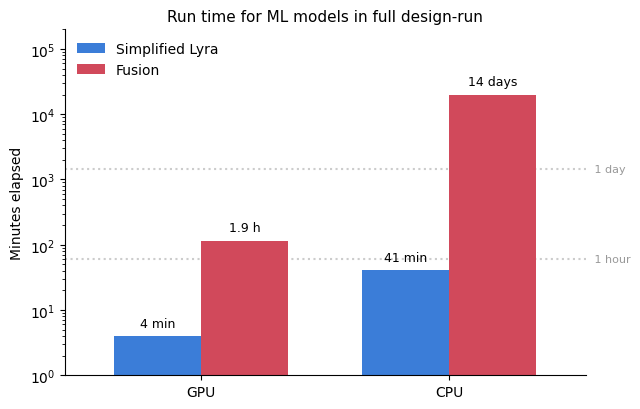

In [2]:
import numpy as np, matplotlib.pyplot as plt

def minutes(secs):
    return secs * N_PREDICTIONS / MEASURED_AT / 60

def label(m):
    if m < 90:    return f"{m:.0f} min"
    if m < 2880:  return f"{m/60:.1f} h"
    return f"{m/1440:.0f} days"

models, devices = list(SECONDS_AT_147620), ["GPU", "CPU"]
colours = ["#3b7dd8", "#d1495b"]
x, w = np.arange(len(devices)), 0.35

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for i, (model, colour) in enumerate(zip(models, colours)):
    pos = x + (i - 0.5) * w
    for p, device in zip(pos, devices):
        m = minutes(SECONDS_AT_147620[model][device])
        ax.bar(p, m, w, color=colour, label=model if device == "GPU" else None)
        ax.text(p, m * 1.4, label(m), ha="center", fontsize=9)

ax.set_yscale("log"); ax.set_ylabel("Minutes elapsed")
ax.set_xticks(x, devices); ax.set_xlim(-0.55, 1.55); ax.set_ylim(1, 2e5)
for m, t in ((60, "1 hour"), (1440, "1 day")):
    ax.axhline(m, color="#ccc", ls=":", zorder=0)
    ax.text(1.57, m, f" {t}", va="center", fontsize=8, color="#999")
ax.set_title(f"Run time for ML models in full design-run", fontsize=11)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("fusion_vs_lyra_runtime.png", dpi=200, bbox_inches="tight")


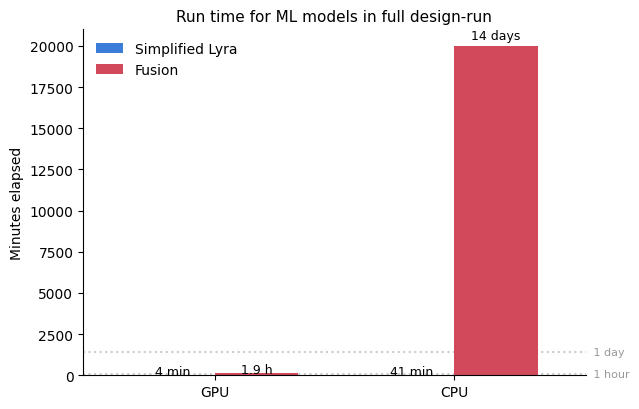

In [3]:
# Same figure, linear y axis. The Fusion CPU bar dwarfs everything else,
# which is itself the point -- but it makes the other three unreadable.
import numpy as np, matplotlib.pyplot as plt

def minutes(secs):
    return secs * N_PREDICTIONS / MEASURED_AT / 60

def label(m):
    if m < 90:    return f"{m:.0f} min"
    if m < 2880:  return f"{m/60:.1f} h"
    return f"{m/1440:.0f} days"

models, devices = list(SECONDS_AT_147620), ["GPU", "CPU"]
colours = ["#3b7dd8", "#d1495b"]
x, w = np.arange(len(devices)), 0.35

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for i, (model, colour) in enumerate(zip(models, colours)):
    pos = x + (i - 0.5) * w
    for p, device in zip(pos, devices):
        m = minutes(SECONDS_AT_147620[model][device])
        ax.bar(p, m, w, color=colour, label=model if device == "GPU" else None)
        ax.text(p, m * 1.02, label(m), ha="center", fontsize=9)

ax.set_ylabel("Minutes elapsed")
ax.set_xticks(x, devices); ax.set_xlim(-0.55, 1.55)
for m, t in ((60, "1 hour"), (1440, "1 day")):
    ax.axhline(m, color="#ccc", ls=":", zorder=0)
    ax.text(1.57, m, f" {t}", va="center", fontsize=8, color="#999")
ax.set_title(f"Run time for ML models in full design-run", fontsize=11)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("fusion_vs_lyra_runtime_linear.png", dpi=200, bbox_inches="tight")
